# 03. v2 모델링 — CNN + 멜 스펙트로그램

**접근법:** 원본 오디오 → 멜 스펙트로그램 (128×128) → Small CNN  
**데이터:** 전체 3,402개 (자연 분포) + `CrossEntropyLoss(weight=...)` 불균형 보정  
**증강:** SpecAugment (주파수 마스킹 + 시간 마스킹)  
**평가:** GroupKFold (group=악기, n_splits=4) — v1과 동일 조건  
**목표:** v1(특징 공학) vs v2(CNN) — 같은 데이터, 같은 검증, 아키텍처만 다른 비교

In [25]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.append('../src')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

from dataset import MelDataset, audio_to_mel
from model import SmallCNN, count_params
from build_dataset import scan_files, downsample

plt.rcParams['figure.dpi'] = 100
CLASSES  = ['ordinario', 'pizzicato_secco', 'tremolo', 'sul_ponticello', 'col_legno_battuto']
V1_DIR         = Path('../results/v1');         V1_DIR.mkdir(parents=True, exist_ok=True)
V2_DIR         = Path('../results/v2');         V2_DIR.mkdir(parents=True, exist_ok=True)
COMPARISON_DIR = Path('../results/comparison'); COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

# 디바이스 설정: MPS (Apple Silicon) > CUDA > CPU 순으로 선택
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')
print(f'Device: {device}')

Device: mps


## 1. 파일 목록 및 클래스 가중치

In [26]:
from sklearn.utils.class_weight import compute_class_weight

df_files  = scan_files()          # 다운샘플링 없이 전체 3,402개

filepaths = df_files['filepath'].values
labels    = df_files['label_id'].values
groups    = df_files['instrument'].values

print(f'Files: {len(filepaths)}')
print(df_files['label'].value_counts().to_string())

# 클래스 불균형 보정 가중치 (소수 클래스에 높은 가중치)
class_w       = compute_class_weight('balanced', classes=np.arange(len(CLASSES)), y=labels)
weight_tensor = torch.FloatTensor(class_w).to(device)
print(f'\n클래스 가중치: {dict(zip(CLASSES, class_w.round(3)))}')


Files: 3402
label
ordinario            1193
tremolo              1041
pizzicato_secco       639
sul_ponticello        302
col_legno_battuto     227

클래스 가중치: {'ordinario': 0.57, 'pizzicato_secco': 1.065, 'tremolo': 0.654, 'sul_ponticello': 2.253, 'col_legno_battuto': 2.997}


## 2. Mel-Spectrogram 사전 계산

3,402개를 한 번에 계산해 메모리에 올려둔다.  
메모리 사용량: 3402 × 128 × 128 × 4byte ≈ **223 MB**

Computing mel-spectrograms: 100%|██████████| 3402/3402 [00:18<00:00, 182.00it/s]


mels shape: (3402, 128, 128),  dtype: float32  (223 MB)


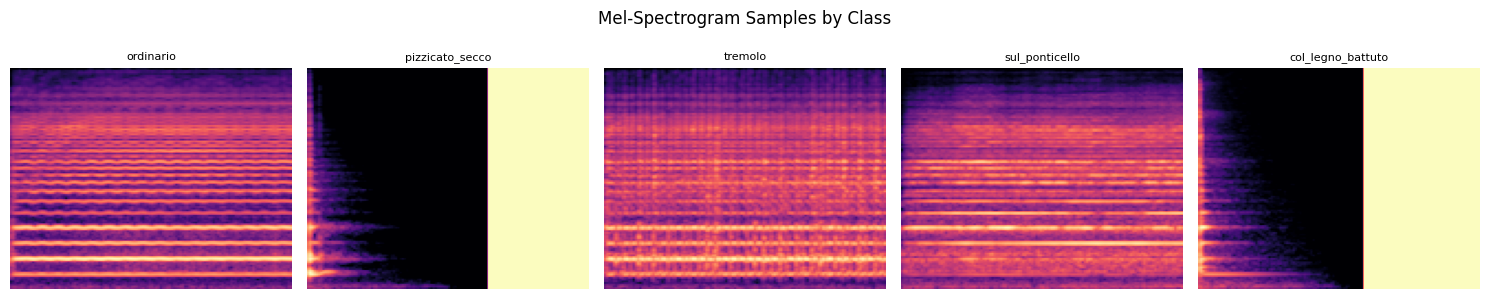

In [27]:
mels = np.stack([
    audio_to_mel(fp)
    for fp in tqdm(filepaths, desc='Computing mel-spectrograms')
])  # (3402, 128, 128)

print(f'mels shape: {mels.shape},  dtype: {mels.dtype}  ({mels.nbytes/1e6:.0f} MB)')

# 예시 시각화
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, cls in zip(axes, CLASSES):
    idx = df_files[df_files['label'] == cls].index[0]
    pos = df_files.index.get_loc(idx)
    ax.imshow(mels[pos], origin='lower', aspect='auto', cmap='magma')
    ax.set_title(cls, fontsize=8)
    ax.axis('off')
plt.suptitle('Mel-Spectrogram Samples by Class')
plt.tight_layout()
plt.savefig(V2_DIR / 'mel_samples.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. 모델 구조

In [28]:
model_test = SmallCNN(n_classes=len(CLASSES))
print(model_test)
print(f'\n학습 가능한 파라미터 수: {count_params(model_test):,}')

# 순전파 shape 확인
dummy = torch.randn(4, 1, 128, 128)
out   = model_test(dummy)
print(f'Input: {dummy.shape}  →  Output: {out.shape}')

SmallCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  

## 4. Training — GroupKFold

v1과 동일한 4-fold (leave-one-instrument-out).  
각 fold마다 모델을 새로 초기화하고 30 epoch 학습한다.

In [29]:
def train_fold(train_idx, test_idx, n_epochs=30, batch_size=32, lr=1e-3):
    train_ds = MelDataset(mels[train_idx], labels[train_idx], augment=True)
    test_ds  = MelDataset(mels[test_idx],  labels[test_idx],  augment=False)
    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=0)
    test_dl  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=0)

    model     = SmallCNN(n_classes=len(CLASSES)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
    criterion = nn.CrossEntropyLoss(weight=weight_tensor)  # 클래스 불균형 보정

    for epoch in range(n_epochs):
        model.train()
        total_loss = 0.0
        for Xb, yb in train_dl:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        scheduler.step()
        if (epoch + 1) % 10 == 0:
            print(f'    epoch {epoch+1:2d}/{n_epochs}  loss={total_loss/len(train_dl):.4f}')

    model.eval()
    all_preds, all_true = [], []
    with torch.no_grad():
        for Xb, yb in test_dl:
            preds = model(Xb.to(device)).argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_true.extend(yb.numpy())

    f1 = f1_score(all_true, all_preds, average='macro')
    # 모델 가중치를 CPU로 옮겨서 반환 (저장용)
    state = {k: v.cpu() for k, v in model.state_dict().items()}
    return f1, np.array(all_true), np.array(all_preds), state

In [30]:
gkf = GroupKFold(n_splits=4)
fold_f1s, fold_true, fold_pred = [], [], []
best_fold_f1, best_fold_state = -1.0, None

for fold, (train_idx, test_idx) in enumerate(gkf.split(mels, labels, groups)):
    test_instrument = np.unique(groups[test_idx])[0]
    print(f'Fold {fold+1}/4  (test: {test_instrument}, n_train={len(train_idx)}, n_test={len(test_idx)})')
    f1, y_true, y_pred, state = train_fold(train_idx, test_idx)
    fold_f1s.append(f1)
    fold_true.append(y_true)
    fold_pred.append(y_pred)
    if f1 > best_fold_f1:
        best_fold_f1, best_fold_state = f1, state
    print(f'  => Test Macro F1: {f1:.4f}\n')

cnn_f1_mean = np.mean(fold_f1s)
cnn_f1_std  = np.std(fold_f1s)
print(f'CNN  Test Macro F1: {cnn_f1_mean:.4f} ± {cnn_f1_std:.4f}')
print(f'Best fold F1: {best_fold_f1:.4f}  (모델 저장 대상)')

Fold 1/4  (test: Viola, n_train=2469, n_test=933)
    epoch 10/30  loss=0.2199
    epoch 20/30  loss=0.1369
    epoch 30/30  loss=0.1252
  => Test Macro F1: 0.8868

Fold 2/4  (test: Violin, n_train=2523, n_test=879)
    epoch 10/30  loss=0.2822
    epoch 20/30  loss=0.1392
    epoch 30/30  loss=0.0964
  => Test Macro F1: 0.8766

Fold 3/4  (test: Contrabass, n_train=2569, n_test=833)
    epoch 10/30  loss=0.2512
    epoch 20/30  loss=0.1238
    epoch 30/30  loss=0.0777
  => Test Macro F1: 0.9008

Fold 4/4  (test: Violoncello, n_train=2645, n_test=757)
    epoch 10/30  loss=0.2572
    epoch 20/30  loss=0.1155
    epoch 30/30  loss=0.0752
  => Test Macro F1: 0.9545

CNN  Test Macro F1: 0.9046 ± 0.0300
Best fold F1: 0.9545  (모델 저장 대상)


## 5. 혼동 행렬 — CNN

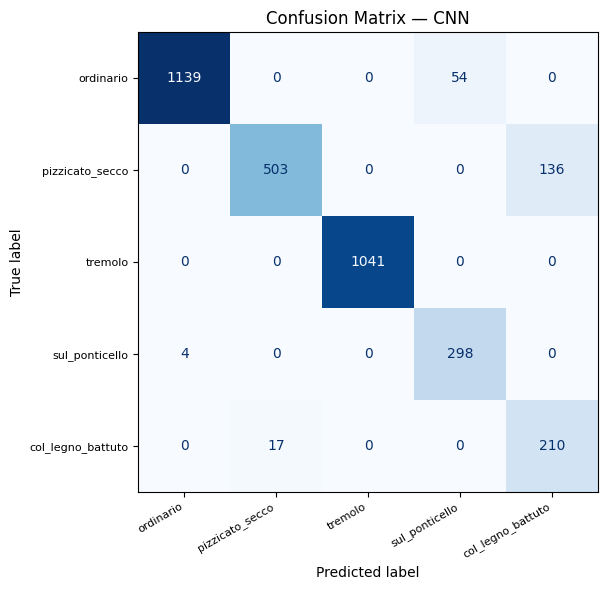

                   precision    recall  f1-score   support

        ordinario       1.00      0.95      0.98      1193
  pizzicato_secco       0.97      0.79      0.87       639
          tremolo       1.00      1.00      1.00      1041
   sul_ponticello       0.85      0.99      0.91       302
col_legno_battuto       0.61      0.93      0.73       227

         accuracy                           0.94      3402
        macro avg       0.88      0.93      0.90      3402
     weighted avg       0.95      0.94      0.94      3402

저장: confusion_matrix_cnn.png, classification_report_cnn.txt


In [31]:
y_true_all = np.concatenate(fold_true)
y_pred_all = np.concatenate(fold_pred)

cm = confusion_matrix(y_true_all, y_pred_all)
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES)
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_xticklabels(CLASSES, rotation=30, ha='right', fontsize=8)
ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_title('Confusion Matrix — CNN')
plt.tight_layout()
plt.savefig(V2_DIR / 'confusion_matrix_cnn.png', dpi=150, bbox_inches='tight')
plt.show()

report = classification_report(y_true_all, y_pred_all, target_names=CLASSES)
print(report)
(V2_DIR / 'classification_report_cnn.txt').write_text(report)
print('저장: confusion_matrix_cnn.png, classification_report_cnn.txt')

,Model,Test F1,Std,Type
0,RF (v1),0.8862,0.0601,v1
1,XGBoost (v1),0.8914,0.0000,v1
2,SVM (v1),0.9159,0.0113,v1
3,CNN (v2),0.9046,0.0300,v2


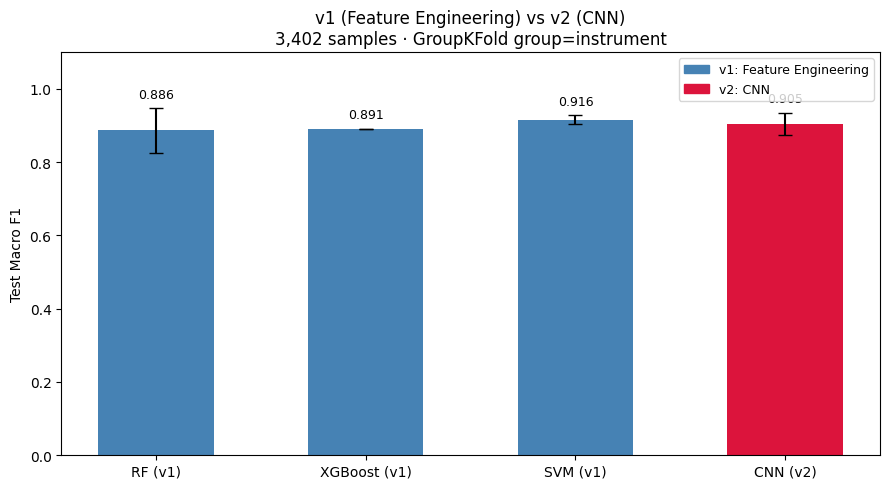

저장: final_comparison.csv, final_comparison.png


In [32]:
# ── 최종 비교: v1(3k) vs v2(3k) ──────────────────────────────────
v1_3k = pd.read_csv(V1_DIR / 'model_comparison.csv')

def _get(df, name, col):
    return df[df['Model'] == name][col].values[0]

final = pd.DataFrame({
    'Model':   ['RF (v1)', 'XGBoost (v1)', 'SVM (v1)', 'CNN (v2)'],
    'Test F1': [
        _get(v1_3k, 'Random Forest',   'Test F1'),
        _get(v1_3k, 'XGBoost (tuned)', 'Test F1'),
        _get(v1_3k, 'SVM',             'Test F1'),
        cnn_f1_mean,
    ],
    'Std': [
        _get(v1_3k, 'Random Forest',   'Std'),
        _get(v1_3k, 'XGBoost (tuned)', 'Std'),
        _get(v1_3k, 'SVM',             'Std'),
        cnn_f1_std,
    ],
    'Type': ['v1', 'v1', 'v1', 'v2'],
})
display(final.round(4))
final.to_csv(COMPARISON_DIR / 'final_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['steelblue', 'steelblue', 'steelblue', 'crimson']
bars = ax.bar(
    final['Model'], final['Test F1'],
    color=colors, yerr=final['Std'], capsize=5,
    error_kw={'elinewidth': 1.5, 'ecolor': 'black'},
    width=0.55,
)
ax.set_ylabel('Test Macro F1')
ax.set_ylim(0, 1.1)
ax.set_title('v1 (Feature Engineering) vs v2 (CNN)\n3,402 samples · GroupKFold group=instrument')

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='steelblue', label='v1: Feature Engineering'),
    Patch(color='crimson',   label='v2: CNN'),
], fontsize=9)

for bar, std_val in zip(bars, final['Std']):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + std_val + 0.02,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(COMPARISON_DIR / 'final_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('저장: final_comparison.csv, final_comparison.png')

## 7. 모델 저장

가장 높은 test F1을 기록한 fold의 CNN 가중치를 `models/cnn_v2.pt`로 저장한다.

In [33]:
MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)

torch.save(best_fold_state, MODELS_DIR / 'cnn_v2.pt')

print('CNN 모델 저장 완료:')
print(f'  {(MODELS_DIR / "cnn_v2.pt").resolve()}')
print(f'  best_fold_f1: {best_fold_f1:.4f}')
print()
print('추론 실행:')
print('  python src/predict.py path/to/audio.wav --model cnn')

CNN 모델 저장 완료:
  /Users/juan/Desktop/실습/주법 분류모델/models/cnn_v2.pt
  best_fold_f1: 0.9545

추론 실행:
  python src/predict.py path/to/audio.wav --model cnn
